***ALUMNOS: RICARDO ALEXIS LAGOS MORA Y MARIANA GONZALEZ***

# **Este conjunto de datos recopila información sobre comportamiento de compra e interacción en una plataforma de comercio electrónico (E-commerce) a nivel de cliente.**

In [2]:
# IMPORTACIÓN DE BIBLIOTECAS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# CARGA DE DATOS Y VISUALIZACIÓN DE VARIABLES

# Cargar el dataset desde GitHub
url = "https://raw.githubusercontent.com/JasonMDev/learning-python-predictive-analytics/master/datasets/Ecom%20Expense.csv"
df = pd.read_csv(url)


pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Primeras 5 filas:")
print(df.head())

print("\nInformación del dataset:")
print(df.info())

print("\nEstadísticas descriptivas:")
print(df.describe())

Primeras 5 filas:
  Transaction ID  Age    Items   Monthly Income  Transaction Time  Record  Gender City Tier  Total Spend
0         TXN001    42       10            7313        627.668127       5  Female    Tier 1  4198.385084
1         TXN002    24        8           17747        126.904567       3  Female    Tier 2  4134.976648
2         TXN003    47       11           22845        873.469701       2    Male    Tier 2  5166.614455
3         TXN004    50       11           18552        380.219428       7  Female    Tier 1  7784.447676
4         TXN005    60        2           14439        403.374223       2  Female    Tier 2  3254.160485

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2362 entries, 0 to 2361
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    2362 non-null   object 
 1   Age               2362 non-null   int64  
 2    Items            2362 non-

In [4]:
print(df.columns.tolist())

['Transaction ID', 'Age ', ' Items ', 'Monthly Income', 'Transaction Time', 'Record', 'Gender', 'City Tier', 'Total Spend']


In [5]:
# Elimina espacios en blanco innecesarios al inicio y final de cada nombre de columna
df.columns = df.columns.str.strip()

In [6]:
# Eliminamos las columnas categoricas del dataset

df=df.drop(["Gender","City Tier"],axis=1)
print(df.columns.values.tolist())


['Transaction ID', 'Age', 'Items', 'Monthly Income', 'Transaction Time', 'Record', 'Total Spend']


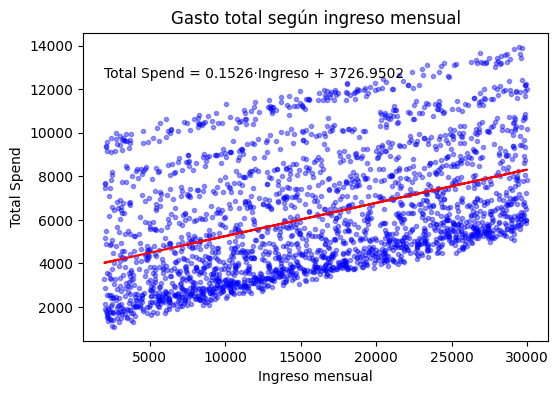

In [23]:
# SCATTER CON RECTA DE REGRESIÓN: Monthly Income vs Total Spend

x_col = df['Monthly Income']
y_col = df['Total Spend']

# Pendiente (a) e intercepto (b) de la recta de regresión simple
a, b = np.polyfit(x_col, y_col, 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x_col, y_col, color='blue', marker='.', alpha=0.4)
ax.plot(x_col, a * x_col + b, color='red')
ax.set_title("Gasto total según ingreso mensual")
ax.set_xlabel("Ingreso mensual")
ax.set_ylabel("Total Spend")
ax.text(2000, 12500, "Total Spend = {a:0.4f}·Ingreso + {b:0.4f}".format(a=a, b=b))
plt.show()

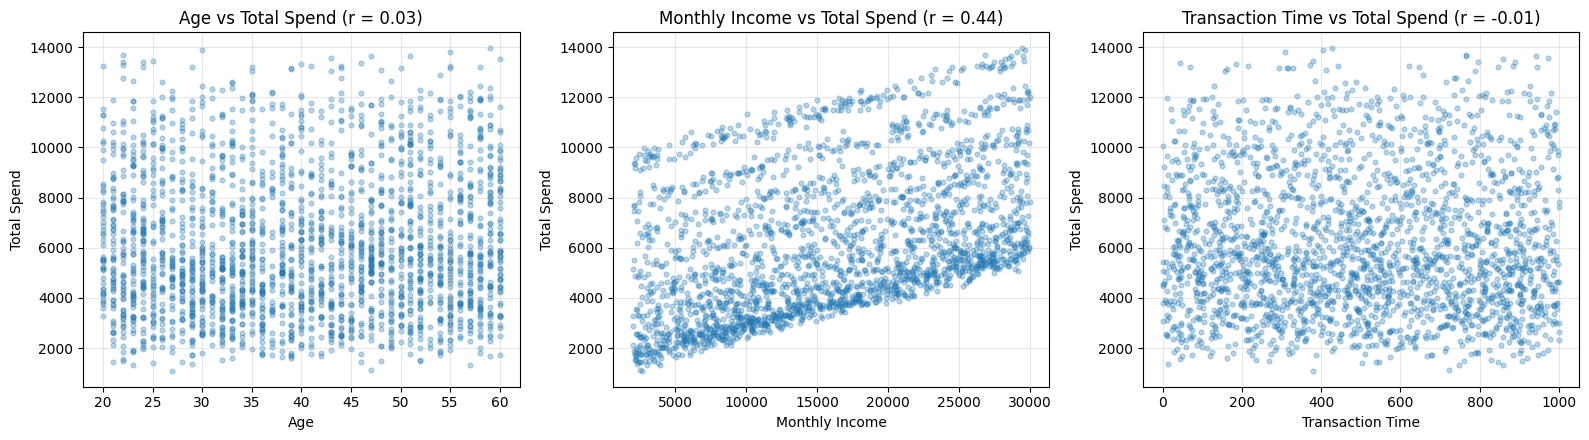

In [21]:
# EXPLORACIÓN: relación de cada variable con Total Spend

features = ['Age', 'Monthly Income', 'Transaction Time']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, features):
    ax.scatter(df[col], df['Total Spend'], alpha=0.3, s=12)
    ax.set_xlabel(col)
    ax.set_ylabel('Total Spend')
    ax.set_title(f'{col} vs Total Spend (r = {df[col].corr(df["Total Spend"]):.2f})')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

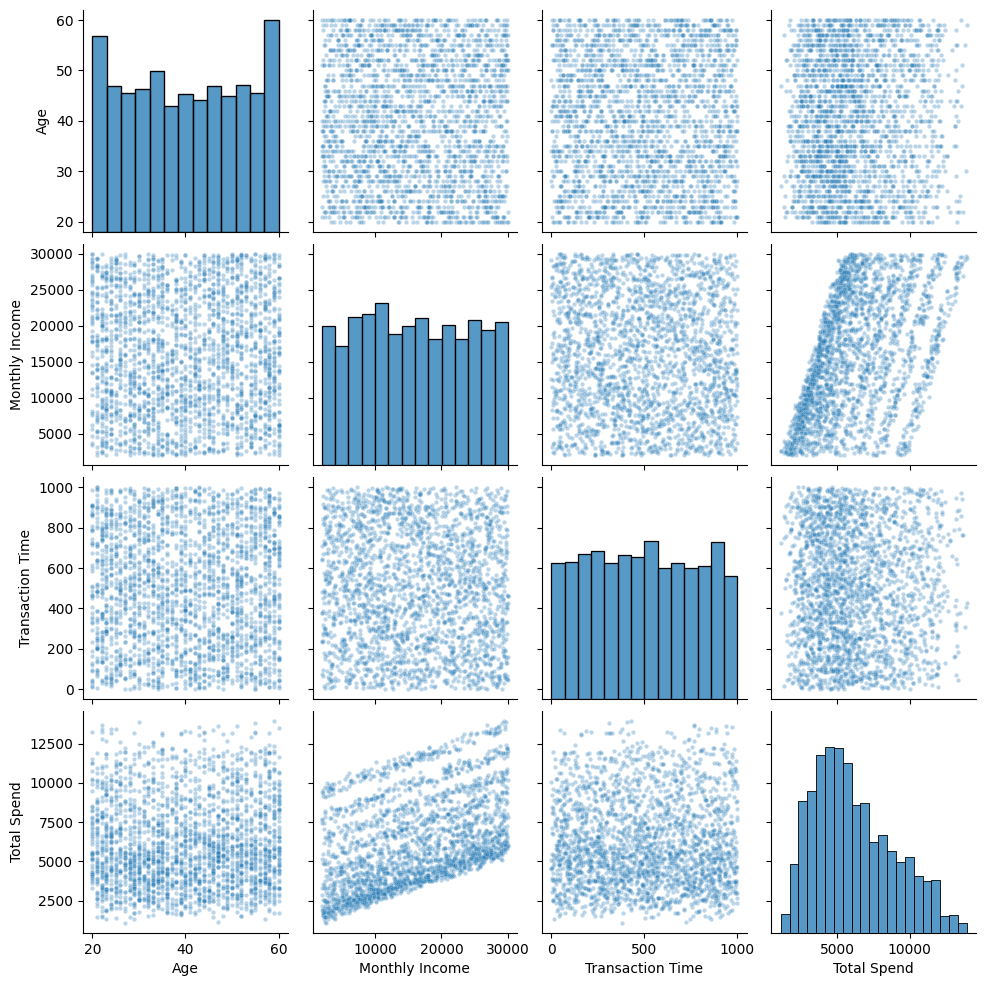

In [22]:
# EXPLORACIÓN: matriz de dispersión (cada variable contra las demás)

sns.pairplot(df[features + ['Total Spend']], plot_kws={'alpha': 0.3, 's': 10})
plt.show()

In [24]:
# CAMBIO DE ESTRUCTURA DE DATOS A MATRICIAL


# Definimos las features (X) y la variable objetivo (Y)
# Elegimos 3 predictores numéricos continuos/discretos

X = df[['Age', 'Monthly Income', 'Transaction Time']].values
y = df['Total Spend'].values

print("Forma de la matriz de características X:", X.shape)
print("Forma del valor objetivo y:", y.shape)

Forma de la matriz de características X: (2362, 3)
Forma del valor objetivo y: (2362,)


In [25]:
# PARTICIONADO DE DATOS EN ENTRENAMIENTO Y TEST


# Reservamos el 80% para entrenamiento y 20% para evaluación
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Datos de Entrenamiento: {X_train.shape[0]} muestras")
print(f"Datos de Test: {X_test.shape[0]} muestras")

Datos de Entrenamiento: 1889 muestras
Datos de Test: 473 muestras


In [10]:
# GENERACIÓN DEL MODELO CON LOS DATOS DE ENTRENAMIENTO

modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Coeficientes e Intercepto
print("\n--- Parámetros del Modelo ---")
print(f"Intercepto (b0): {modelo.intercept_:.4f}")
for feature, coef in zip(['Age', 'Monthly Income', 'Transaction Time'], modelo.coef_):
    print(f"Coeficiente para {feature}: {coef:.4f}")


--- Parámetros del Modelo ---
Intercepto (b0): 3025.8040
Coeficiente para Age: 9.5822
Coeficiente para Monthly Income: 0.1597
Coeficiente para Transaction Time: 0.3861


In [12]:
# EVALUACIÓN DEL MODELO CON LOS DATOS DE ENTRENAMIENTO

y_train_pred = modelo.predict(X_train)

mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)

print("\n Evaluación en Entrenamiento ")
print()
print(f"MSE Train: {mse_train:.4f}")
print(f"RMSE Train: {rmse_train:.4f}")
print(f"R² Train: {r2_train:.4f}")


 Evaluación en Entrenamiento 

MSE Train: 6363042.1885
RMSE Train: 2522.5071
R² Train: 0.2065


In [14]:
# EVALUACIÓN DEL MODELO CON LOS DATOS DE TEST

y_test_pred = modelo.predict(X_test)

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_test_pred)

print("\n--- Evaluación en Test ---")
print(f"MSE Test: {mse_test:.4f}")
print(f"RMSE Test: {rmse_test:.4f}")
print(f"R² Test: {r2_test:.4f}")


--- Evaluación en Test ---
MSE Test: 6191305.9586
RMSE Test: 2488.2335
R² Test: 0.1272


# ***GRÁFICOS***

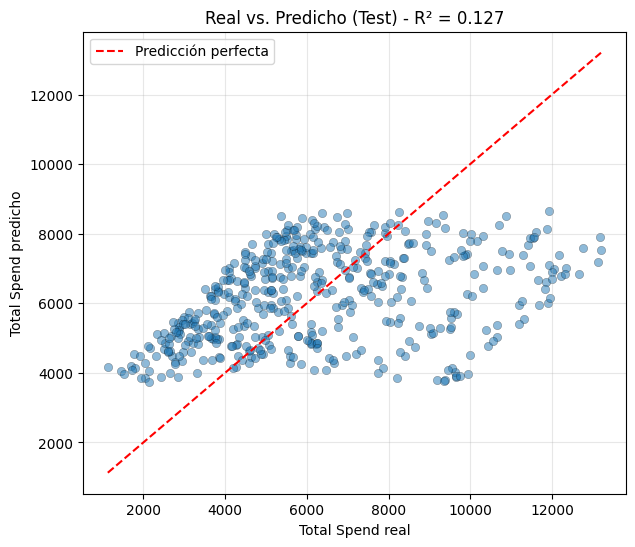

In [26]:
# Valores reales vs. predichos (TEST)
# Si el modelo fuera perfecto, los puntos caerían sobre la línea roja.

features = ['Age', 'Monthly Income', 'Transaction Time']

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.5, edgecolor='k', linewidth=0.3)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
plt.plot(lims, lims, 'r--', label='Predicción perfecta')
plt.xlabel('Total Spend real')
plt.ylabel('Total Spend predicho')
plt.title(f'Real vs. Predicho (Test) - R² = {r2_test:.3f}')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

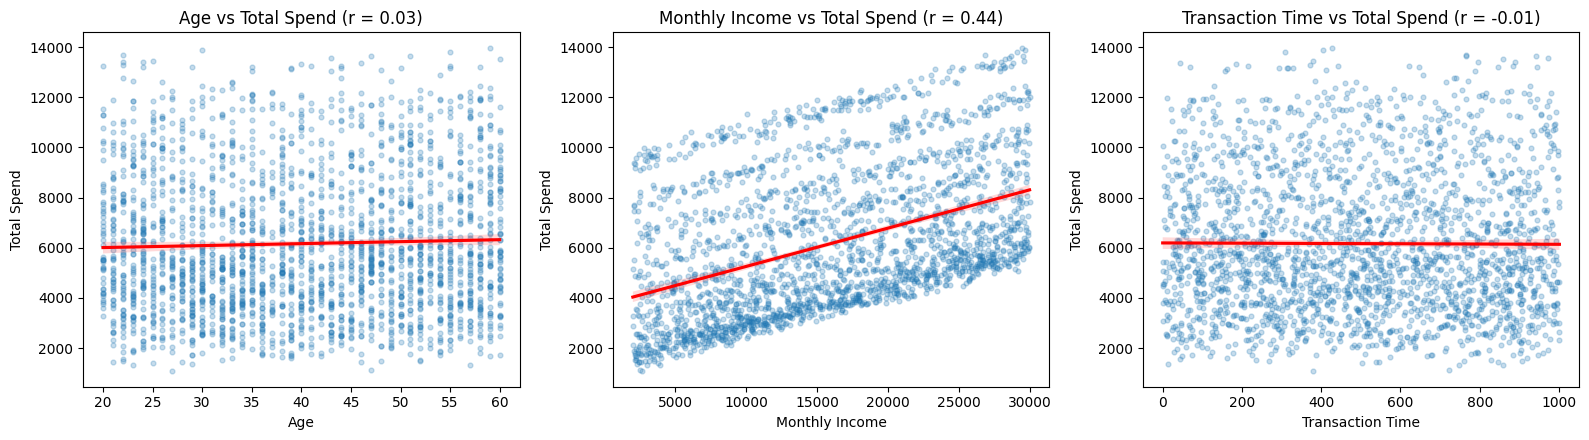

In [17]:
# Cada feature vs. Total Spend (scatter + línea de tendencia)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, features):
    sns.regplot(x=df[col], y=df['Total Spend'], ax=ax,
                scatter_kws={'alpha': 0.25, 's': 12}, line_kws={'color': 'red'})
    corr = df[col].corr(df['Total Spend'])
    ax.set_title(f'{col} vs Total Spend (r = {corr:.2f})')
plt.tight_layout()
plt.show()

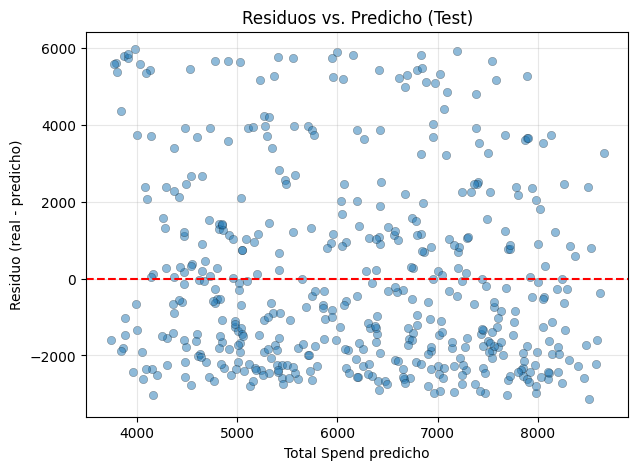

In [18]:
# Residuos vs. valores predichos (TEST)
# Una nube sin patrón alrededor de 0 es lo ideal.

residuos = y_test - y_test_pred
plt.figure(figsize=(7, 5))
plt.scatter(y_test_pred, residuos, alpha=0.5, edgecolor='k', linewidth=0.3)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Total Spend predicho')
plt.ylabel('Residuo (real - predicho)')
plt.title('Residuos vs. Predicho (Test)')
plt.grid(alpha=0.3)
plt.show()

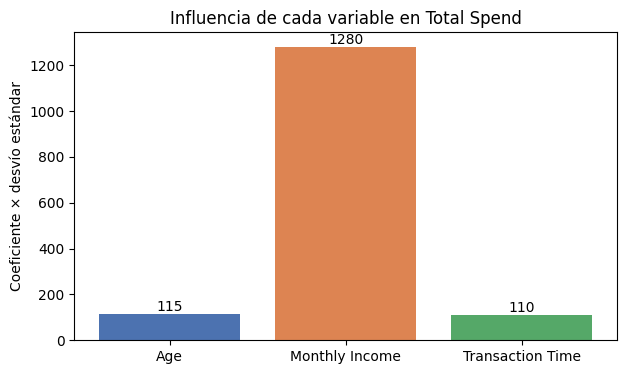

In [27]:
# Importancia de cada variable (coeficientes × desvío estándar)
# Permite comparar variables con escalas distintas.

efecto = modelo.coef_ * X_train.std(axis=0)

plt.figure(figsize=(7, 4))
bars = plt.bar(features, efecto, color=['#4C72B0', '#DD8452', '#55A868'])
plt.bar_label(bars, fmt='%.0f')
plt.ylabel('Coeficiente × desvío estándar')
plt.title('Influencia de cada variable en Total Spend')
plt.show()

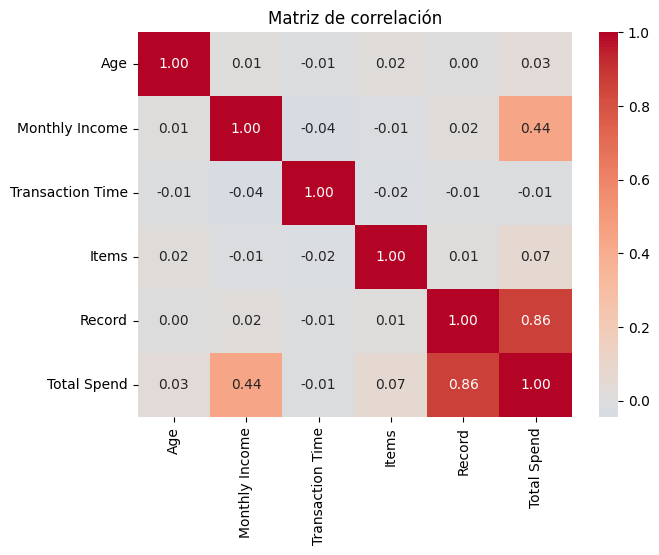

In [28]:
# CELDA 5: Matriz de correlación

plt.figure(figsize=(7, 5))
sns.heatmap(df[features + ['Items', 'Record', 'Total Spend']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlación')
plt.show()